# Exploration du dataset

Ce notebook justifie le choix des données : pourquoi ScienceQA a été écarté, ce que contient MMMLU en français et comment les matières sont réparties. Il lit la copie locale créée par `python -m src.data_loader`.

## 1. Pourquoi pas ScienceQA ?

Effectifs relevés le 5 novembre 2026 sur le jeu d'entraînement de `derek-thomas/ScienceQA` (12 726 questions), via l'API `datasets-server` de Hugging Face :

| Matière visée | Valeur de `topic` | Questions |
|---|---|---|
| Biologie | biology | 2 464 |
| Physique | physics | 1 923 |
| Chimie | chemistry | 735 |
| Histoire | us-history + world-history | 361 |
| Mathématiques | aucune | 0 |

Le dataset n'a **aucune question de mathématiques** et il est **uniquement en anglais**. Il ne permet donc pas d'atteindre l'objectif sans inventer des étiquettes.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path("..").resolve()))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.data_loader import RAW_FILE, SUBJECT_TO_LABEL, select_subjects
from src.preprocessing import clean_text, tokenize

raw = pd.read_csv(RAW_FILE)
print(raw.shape)
print(raw.columns.tolist())
print("Sous-matières :", raw["Subject"].nunique())
print("Valeurs manquantes dans Question :", raw["Question"].isna().sum())

(14042, 8)
['Unnamed: 0', 'Question', 'A', 'B', 'C', 'D', 'Answer', 'Subject']
Sous-matières : 57
Valeurs manquantes dans Question : 0


## 2. Du dataset brut aux cinq matières

Seules les colonnes `Question` et `Subject` servent. Les choix de réponses A à D ne sont pas utilisés : l'application ne reçoit que la question.

In [2]:
mapping = (
    raw[raw["Subject"].isin(SUBJECT_TO_LABEL)]
    .groupby("Subject").size().rename("questions").reset_index()
)
mapping["matière"] = mapping["Subject"].map(SUBJECT_TO_LABEL)
mapping.sort_values(["matière", "Subject"]).reset_index(drop=True)

,Subject,questions,matière
0,college_biology,144,Biologie
1,high_school_biology,310,Biologie
2,college_chemistry,100,Chimie
3,high_school_chemistry,203,Chimie
4,high_school_european_history,165,Histoire
5,high_school_us_history,204,Histoire
6,high_school_world_history,237,Histoire
7,prehistory,324,Histoire
8,abstract_algebra,100,Mathématiques
9,college_mathematics,100,Mathématiques


Avant dédoublonnage : 3023
Après dédoublonnage : 2950


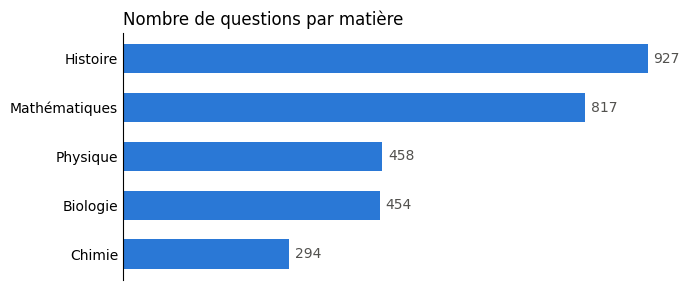

In [3]:
df = select_subjects(raw)
print("Avant dédoublonnage :", raw["Subject"].isin(SUBJECT_TO_LABEL).sum())
print("Après dédoublonnage :", len(df))
counts = df["label"].value_counts()

fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(counts.index[::-1], counts.values[::-1], color="#2a78d6", height=0.6)
for y, value in enumerate(counts.values[::-1]):
    ax.text(value + 10, y, value, va="center", color="#52514e")
ax.set_title("Nombre de questions par matière", loc="left")
ax.spines[["top", "right", "bottom"]].set_visible(False)
ax.set_xticks([])
ax.tick_params(length=0)
plt.tight_layout()
plt.show()

Les classes sont déséquilibrées : la chimie est environ trois fois moins représentée que l'histoire. L'entraînement compense donc avec des poids de classe, et l'évaluation regarde le F1 macro en plus de l'exactitude.

## 3. Exemples de questions

In [4]:
pd.set_option("display.max_colwidth", 110)
df.groupby("label").sample(2, random_state=0)[["label", "source_subject", "question"]]

,label,source_subject,question
221,Biologie,college_biology,Une réponse comportementale appelée modèle d'action fixe présenté par les animaux
151,Biologie,college_biology,Lequel des facteurs suivants ne favorise PAS le déséquilibre de liaison ?
255,Chimie,college_chemistry,Quelle phrase explique le plus clairement pourquoi le piégeage de spin est souvent utilisé pour détecter l...
1531,Chimie,high_school_chemistry,"Une solution contient un mélange de quatre composés différents : KCl(aq), Fe(NO3)3(aq), MgSO4(aq) et N2H4(..."
2676,Histoire,prehistory,Quand les Aborigènes occupaient-ils les terres intérieures arides de l’Australie ?
2724,Histoire,prehistory,Les pratiques de subsistance des populations peuvent être déterminées en récupérant et étudiant :
1784,Mathématiques,high_school_mathematics,Quelle est la somme de toutes les valeurs de nombres entiers positifs de $n$ telle que $n^2$ est un facteu...
1803,Mathématiques,high_school_mathematics,"Dans le parallélogramme $ABCD$, l’angle $B$ mesure $110^\circ$. Quel est le nombre de degrés dans la mesur..."
510,Physique,college_physics,Lequel des lasers suivants utilise des transitions impliquant les niveaux d’énergie des atomes libres ?
2097,Physique,high_school_physics,Le poids d’une boîte sur la Terre est de 80 N. Quel est le poids de la boîte sur la Lune si la Lune a 1/80...


## 4. Effet du prétraitement

In [5]:
example = "Quelle est la composition chimique de l'eau ?"
print("Original  :", example)
print("Nettoyé   :", clean_text(example))
print("Jetons    :", tokenize(example))

Original  : Quelle est la composition chimique de l'eau ?
Nettoyé   : quelle est la composition chimique de l'eau ?
Jetons    : ['quelle', 'composition', 'chimique', 'eau']


## 5. Longueur des questions

Cette répartition a guidé le test de la longueur maximale des séquences. La plupart des questions sont courtes, mais certaines contiennent de longs extraits de documents.

count    2950.0
mean       40.0
std        53.5
min         1.0
50%        16.0
75%        35.0
95%       161.0
max       366.0
Part des questions de 60 jetons ou moins : 80.7%
label
Biologie         12.0
Chimie           13.0
Histoire         97.0
Mathématiques    17.0
Physique         12.0


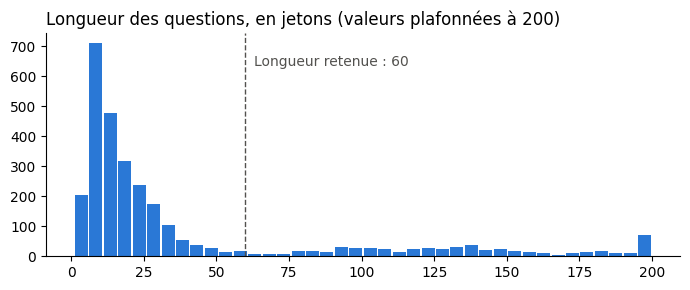

In [6]:
lengths = df["question"].map(lambda q: len(tokenize(q)))
print(lengths.describe(percentiles=[0.5, 0.75, 0.95]).round(1).to_string())
print("Part des questions de 60 jetons ou moins :", f"{(lengths <= 60).mean():.1%}")
print(lengths.groupby(df["label"]).median().rename("médiane").to_string())

fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(lengths.clip(upper=200), bins=40, color="#2a78d6", rwidth=0.9)
ax.axvline(60, color="#52514e", linestyle="--", linewidth=1)
ax.text(63, ax.get_ylim()[1] * 0.85, "Longueur retenue : 60", color="#52514e")
ax.set_title("Longueur des questions, en jetons (valeurs plafonnées à 200)", loc="left")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()